In [16]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

set_style()

run_query("SELECT COUNT(*) AS n FROM dwd_orders")

,n
0,99441


恒等式校验：
检查approve_days seller_days transit_days 三者不为NULL的订单中, 加起来等于delivery_days的比例

In [17]:
sql = """
SELECT SUM(CASE WHEN approve_days + seller_days + transit_days = delivery_days THEN 1 END) AS right_time, 
       AVG(CASE WHEN approve_days + seller_days + transit_days = delivery_days THEN 1 ELSE 0 END) AS rate_right
FROM dws_order_fulfillment
WHERE approve_days IS NOT NULL AND seller_days IS NOT NULL AND transit_days IS NOT NULL
"""
df = run_query(sql)
df

,right_time,rate_right
0,95498.0,1.0


查看订单距离

In [18]:
# 最大订单距离
sql_max_dis = """
SELECT MAX(distance_km) 
FROM dws_order_fulfillment;
"""
run_query(sql_max_dis)

,MAX(distance_km)
0,3399.2


In [19]:
#查询距离超过4500KM的订单数
sql = """
SELECT COUNT(*) AS dis_big_than_4500
FROM dws_order_fulfillment
WHERE distance_km > 4500;
"""
run_query(sql)

,dis_big_than_4500
0,0


分段分析不同延误程度的差评率: 

In [20]:
# 查看各分段差评率
sql_delay = """
SELECT CASE
         WHEN delay_days <= -8 THEN '1 提前8天以上'
         WHEN delay_days <= -1 THEN '2 提前1-7天'
         WHEN delay_days = 0   THEN '3 承诺日当天'
         WHEN delay_days <= 3  THEN '4 晚1-3天'
         WHEN delay_days <= 7  THEN '5 晚4-7天'
         WHEN delay_days <= 14 THEN '6 晚8-14天'
         ELSE '7 晚15天以上'
       END                                  AS delay_group,
       COUNT(*)                             AS orders,
       SUM(has_review)                      AS reviewed,
       SUM(is_bad_review)                   AS bad_reviews,
       AVG(is_bad_review)                   AS bad_rate,
       AVG(review_score)                    AS avg_score,
       AVG(1 - has_review)                  AS no_review_rate,
       AVG(is_review_before_delivery)       AS review_before_delivery_rate
FROM dws_order_fulfillment
GROUP BY delay_group
ORDER BY delay_group
"""
df_delay = run_query(sql_delay)
df_delay

,delay_group,orders,reviewed,bad_reviews,bad_rate,avg_score,no_review_rate,review_before_delivery_rate
0,1 提前8天以上,71046,70673.0,6326.0,0.0895,4.3178,0.0053,0.0022
1,2 提前1-7天,17335,17229.0,1762.0,0.1023,4.2011,0.0061,0.0032
2,3 承诺日当天,1291,1280.0,159.0,0.1242,4.0336,0.0085,0.0063
3,4 晚1-3天,1869,1851.0,595.0,0.3214,3.2907,0.0096,0.2085
4,5 晚4-7天,1802,1748.0,1183.0,0.6768,2.1030,0.0300,0.9068
5,6 晚8-14天,1478,1446.0,1159.0,0.8015,1.6708,0.0217,0.9993
6,7 晚15天以上,1382,1333.0,1044.0,0.7832,1.7247,0.0355,1.0000


In [21]:
#延误与否的整体对比
sql_late = """
SELECT is_late,
       COUNT(*)            AS orders,
       AVG(is_bad_review)  AS bad_rate,
       AVG(review_score)   AS avg_score
FROM dws_order_fulfillment
GROUP BY is_late
"""
df_late = run_query(sql_late)
df_late

,is_late,orders,bad_rate,avg_score
0,0,89672,0.0925,4.2912
1,1,6531,0.6242,2.2706


In [22]:
#差评里有多少延误订单
sql_share = """
SELECT SUM(is_bad_review = 1 AND is_late = 1) / SUM(is_bad_review = 1) AS share_bad_from_late
FROM dws_order_fulfillment
"""
run_query(sql_share)

,share_bad_from_late
0,0.3256


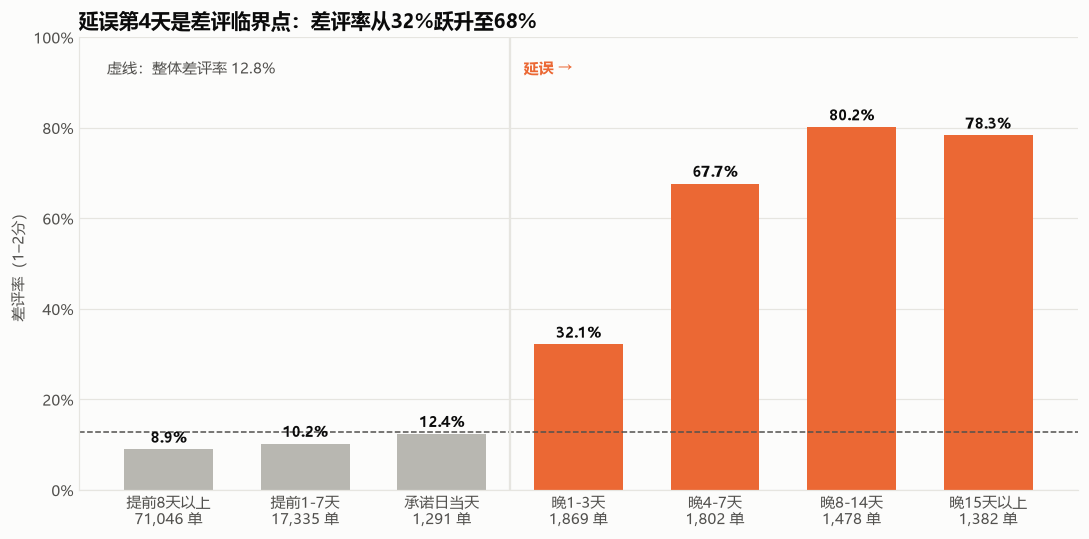

In [23]:
from matplotlib.ticker import FuncFormatter

# 横轴标签：分段名（去掉编号）+ 换行 + 订单数
labels = [f"{g[2:]}\n{n:,} 单" for g, n in zip(df_delay["delay_group"], df_delay["orders"])]
overall = df_delay["bad_reviews"].sum() / df_delay["reviewed"].sum()   # 整体差评率

# 填空1：延误的分段用橙色，其余用灰色。
#        分段名都以编号开头，延误的分段编号是几到几？用字符串比较写出条件
colors = [COLORS["orange"] if g >= "4" else COLORS["gray"] for g in df_delay["delay_group"]]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, df_delay["bad_rate"] * 100, color=colors, width=0.65)

# 柱子上方标出差评率
for i, r in enumerate(df_delay["bad_rate"]):
    ax.text(i, r * 100 + 1.5, f"{r:.1%}", ha="center", fontsize=10, fontweight="bold", color=COLORS["text"])

# 参考线：整体差评率
ax.axhline(overall * 100, color=COLORS["text_secondary"], linewidth=1, linestyle="--")
ax.text(-0.45, 92, f"虚线：整体差评率 {overall:.1%}", fontsize=9.5, color=COLORS["text_secondary"])

# 填空2：在"未延误"和"延误"之间画一条竖直分隔线。
#        柱子的位置是 0, 1, 2, ...，分隔线应该放在第几根和第几根柱子之间？
ax.axvline(2.5, color=COLORS["grid"], linewidth=1.5)
ax.text(2.6, 92, "延误 →", fontsize=10, color=COLORS["orange"], fontweight="bold")

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("差评率（1–2分）")

# 填空3：结论标题
ax.set_title("延误第4天是差评临界点：差评率从32%跃升至68%")
fig.tight_layout()
fig.savefig("../docs/figures/m3_delay_bad_review.png", dpi=150, bbox_inches="tight")
plt.show()

当前已经发现延误是导致差评率的重要原因之一，但是我们要细扣到底是 卖家慢 还是 物流慢

分析方法：建立2x2交叉表，列：“最终准时”, “最终延误”；行：“卖家准时”, “卖家延误”

In [27]:
sql = """
SELECT
    is_seller_late,
    is_late,
    COUNT(*)                          AS orders,
    SUM(has_review)                   AS reviewed,
    ROUND(AVG(is_bad_review), 4)      AS bad_rate,
    ROUND(AVG(review_score), 2)       AS avg_score,
    ROUND(AVG(seller_days), 1)        AS avg_seller_days,
    ROUND(AVG(transit_days), 1)       AS avg_transit_days
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
GROUP BY is_seller_late, is_late
ORDER BY is_seller_late, is_late;
"""
df = run_query(sql)
print(df["orders"].sum())
df

94930


,is_seller_late,is_late,orders,reviewed,bad_rate,avg_score,avg_seller_days,avg_transit_days
0,0,0,81692,81266.0,0.0835,4.33,2.1,8.0
1,0,1,4708,4603.0,0.6213,2.27,2.4,31.6
2,1,0,6721,6670.0,0.1321,4.09,7.9,7.7
3,1,1,1809,1762.0,0.6311,2.27,13.2,18.3


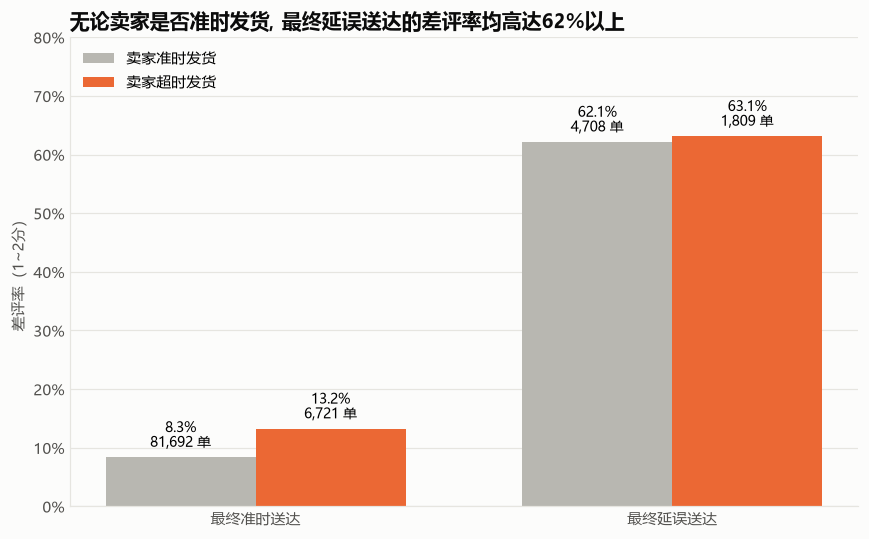

In [29]:
import numpy as np
import matplotlib.ticker as mticker

pv   = df.pivot(index="is_late", columns="is_seller_late", values="bad_rate")
pv_n = df.pivot(index="is_late", columns="is_seller_late", values="orders")

x = np.arange(len(pv.index))
w = 0.36
fig, ax = plt.subplots(figsize=(8, 5))

for i, (col, label, color) in enumerate([
        (0, "卖家准时发货", COLORS["gray"]),
        (1, "卖家超时发货", COLORS["orange"])]):
    bars = ax.bar(x + (i - 0.5) * w, pv[col], width=w, color=color, label=label)
    for b, n in zip(bars, pv_n[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                f"{b.get_height():.1%}\n{n:,} 单", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(["最终准时送达", "最终延误送达"])
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel("差评率（1~2分）")
ax.legend(frameon=False, loc="upper left")
ax.set_title("无论卖家是否准时发货, 最终延误送达的差评率均高达62%以上", loc="left")

fig.tight_layout()
fig.savefig("../docs/figures/m3_seller_vs_logistics.png", dpi=150, bbox_inches="tight")
plt.show()